In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import json


# Configuring display settings
plt.rcParams['figure.figsize'] = (12, 9)
sns.set()
sns.set_context('talk')
np.set_printoptions(threshold=20, precision=2, suppress=True)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)
pd.set_option('display.float_format', '{:.2f}'.format)
warnings.filterwarnings("ignore", category=FutureWarning)


In [2]:
# Import config variable
with open("../../config.json") as f:
    cfg = json.load(f)
    
target = cfg["rc"]        
file_name = cfg["rc_file_name"]   
random_state = cfg["split"]["random_state"]  
# Load the dataset
data = pd.read_csv(f"../../data/{file_name}.csv")

In [3]:
from sklearn.model_selection import train_test_split 
X = data.drop(columns=[target])
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Training set size: 307 samples
Test set size: 77 samples


Fitting 5 folds for each of 1296 candidates, totalling 6480 fits
Meilleurs paramètres: {'colsample_bytree': 0.6, 'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 1000, 'reg_alpha': 1.0, 'reg_lambda': 3.0, 'subsample': 0.7}
Meilleur R² (CV): 0.8561144948005677

MAE (test): 1.8112759590148926
RMSE (test): 2.4587803665869146
R² (test): 0.9148221611976624
R² (train): 0.9340513348579407


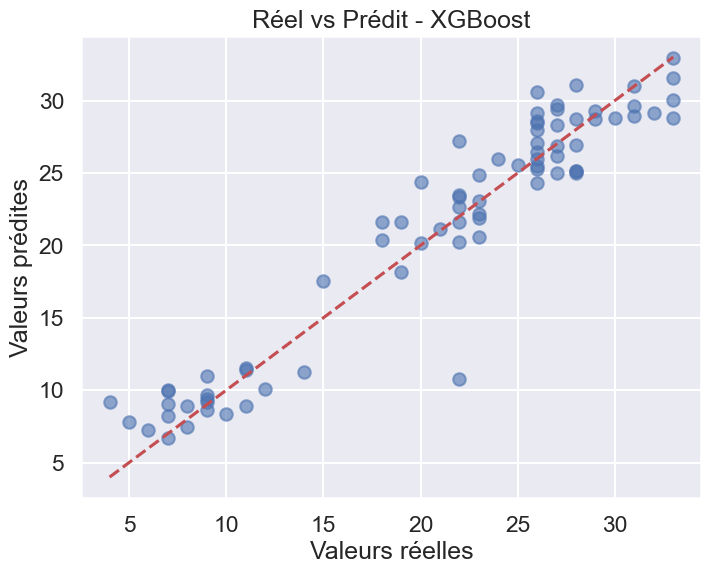

In [4]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

param_grid = {
    'n_estimators': [800, 1000, 1500],
    'learning_rate': [0.005, 0.01],
    'max_depth': [2, 3, 4],
    'min_child_weight': [5, 7, 10],
    'colsample_bytree': [0.5, 0.6],
    'subsample': [0.6, 0.7],
    'reg_alpha': [1.0, 2.0, 3.0], 
    'reg_lambda': [2.0, 3.0],
}


grid_search = GridSearchCV(
    XGBRegressor(),
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Meilleurs paramètres:", grid_search.best_params_)
print("Meilleur R² (CV):", grid_search.best_score_)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print("\nMAE (test):", mean_absolute_error(y_test, y_pred_best))
print("RMSE (test):", np.sqrt(mean_squared_error(y_test, y_pred_best)))
print("R² (test):", r2_score(y_test, y_pred_best))
print("R² (train):", r2_score(y_train, best_model.predict(X_train)))

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Réel vs Prédit - XGBoost')
plt.show()


In [10]:
import joblib

joblib.dump(best_model, 'saved_models/xgboost_rc.pkl')

['saved_models/xgboost_rc.pkl']

In [5]:
from lightgbm import LGBMRegressor

best_model_lgb = LGBMRegressor(
    n_estimators=1500,
    learning_rate=0.01,
    max_depth=3,
    num_leaves=15,  # LightGBM n'a pas max_depth "direct", c'est via num_leaves
    min_child_samples=5,
    subsample=0.7,
    colsample_bytree=0.6,
    reg_alpha=1.0,
    reg_lambda=2.0,
    random_state=42
)

best_model_lgb.fit(X_train, y_train)
y_pred_lgb = best_model_lgb.predict(X_test)

print("R² test:", r2_score(y_test, y_pred_lgb))
print("R² train:", r2_score(y_train, best_model_lgb.predict(X_train)))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000612 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 108
[LightGBM] [Info] Number of data points in the train set: 307, number of used features: 18
[LightGBM] [Info] Start training from score 22.459283
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best ga

In [ ]:
import joblib

joblib.dump(best_model, 'saved_models/lightgbm_rc.pkl')

['saved_models/xgboost_rc.pkl']